# mmBERT (head+tail 1024) + stylometric features (including from eda), 30k training rows

**Features** (computed on the full text unless noted)
- **Stylometry (spaCy, `en_core_web_sm` / `de_core_news_sm`)**: universal POS-tag ratios (the same tag set for EN and DE), stop-word share, lexical density, noun/verb ratio, POS entropy and POS-bigram diversity, parse-tree depth, dependency distance, past-tense share, 1st/2nd-person pronouns, and spaCy sentence-length statistics. Runs on the first `SPACY_MAX_CHARS` characters to keep run time reasonable.
- **Burstiness**: sentence-length CV and Goh–Barabási burstiness `(σ−μ)/(σ+μ)`, local burstiness (mean |Δ length| between neighbouring sentences), word-recurrence burstiness (gaps between repeats of the same word), and spread of word length across sentences.
- **Digits**: digit-char ratio, share of words with digits, numbers / years / `%` per 100 words, share of sentences with a digit.
- **Untypeable non-ASCII symbols**: characters a person can't normally type on a phone / laptop keyboard: em/en dashes and other dash variants, curly quotes, the `…` character, non-breaking / zero-width / thin spaces, and bullets, arrows, math signs, `™` etc. **Not counted**: emoji (humans use them), any letter (German umlauts / ß, accents via long-press), and common keyboard symbols (`€ £ ° §`). Rates per 1k chars per group, em dash separately, distinct count, share of sentences containing one, curly-vs-straight apostrophe share, and **mixed straight + curly quotes in one text** (a fusion cue: human text with AI-inserted sentences).
- **Commas per word**: global rate, per-sentence mean / std / max, share of sentences without a comma.
- Extra: lexical richness (TTR@300, hapax, Yule's K), other punctuation, casing, and **intra-text drift**, i.e. how much the most unusual sentence deviates from the rest (aimed at `fusion`).

**How the features are used**
1. **Fusion inside the model**: features are quantile-normalised → 2-layer MLP → concatenated with mmBERT's pooled [CLS] + mean embedding → classifier. Trained end to end. Two auxiliary heads (text-only, features-only, loss weight `AUX_W`) keep both branches useful, so the backbone doesn't get lazy. They also show on validation how much each part contributes.
2. **Stacking (stage 2)**: LightGBM on the validation rows (5-fold CV, out-of-fold → honest score). Inputs: fused-model probabilities (head+tail), statistics of sliding-window chunk probabilities (mean / max / min / std per class; max-`fusion` over chunks targets locally inserted AI text), raw handcrafted features, lang and domain. Plus class-bias tuning for macro-F1, done with nested CV.
3. The best candidate by validation macro-F1 is used for `submission.csv`.

The validation split (20k rows) is the same code and seed as the earlier notebooks, so the scores are directly comparable.

**Kaggle**: GPU T4 x2, Internet on (model + spaCy models). Rough run time: features ~15–25 min (CPU), training ~1.2–1.5 h, inference + stacking ~40 min. Features are cached in `/kaggle/working/feat_cache`.

## Setup & config

In [1]:
import os, re, gc, sys, time, math, random, socket, subprocess, warnings, importlib, unicodedata
from collections import Counter, defaultdict
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, FileLink

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from joblib import Parallel, delayed

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

import transformers
from packaging import version
if version.parse(transformers.__version__) < version.parse("4.48.0"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.48.0"], check=True)
    raise SystemExit("transformers was upgraded: restart the kernel (Run -> Restart) and run again.")
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False
print("torch", torch.__version__, "| transformers", transformers.__version__, "| lightgbm", HAS_LGB)

# ---------------- config ----------------
QUICK = os.environ.get("QUICK", "0") == "1"    # tiny smoke-test run (set env QUICK=1)

MODEL_NAME   = "jhu-clsp/mmBERT-base"
RANDOM_STATE = 42          # same seed + split code as the earlier notebooks -> identical validation rows
VAL_N        = 20_000
TRAIN_N      = 30_000      # <- 30k training rows
MAX_LEN      = 1024        # best run: head + tail at 1024 tokens
HEAD_TOKENS  = 256
CHUNK_STRIDE = 768         # sliding-window chunks, used only for stage-2 stacking features
EPOCHS       = 2
BATCH_SIZE   = 16          # total over all GPUs
GRAD_ACCUM   = 1
LR           = 3e-5        # backbone
HEAD_LR      = 5e-4        # new layers (feature MLP + fusion head)
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
EVAL_BATCH   = 32
N_EVALS      = 6

# feature fusion
FEAT_HIDDEN  = 128         # width of the feature MLP
HEAD_DROPOUT = 0.1
AUX_W        = 0.2         # weight of the auxiliary text-only / feature-only losses
FEAT_NOISE   = 0.05        # gaussian noise on normalised features during training (regularisation)

# features
USE_SPACY       = True
SPACY_MAX_CHARS = 3000
SPACY_BATCH     = 64
SPACY_PROCS     = max(os.cpu_count() or 1, 1)

# stage 2
USE_CHUNKS    = True       # chunk-probability statistics as stacker features (extra inference time)
N_FOLDS_STACK = 5
SAVE_MODEL    = False

if QUICK:
    VAL_N, TRAIN_N, MAX_LEN, HEAD_TOKENS, CHUNK_STRIDE = 1_000, 2_000, 256, 64, 192
    SPACY_MAX_CHARS = 1000

TEXT, LANG, DOMAIN, LABEL = "text", "lang", "domain", "label"
CLASSES = ["human", "ai", "fusion"]
LANGS = ["en-EN", "de-DE"]
LABEL2ID = {c: i for i, c in enumerate(CLASSES)}

OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
FEAT_DIR = OUT_DIR / "feat_cache"
FEAT_DIR.mkdir(exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPU = torch.cuda.device_count()
if DEVICE.type == "cuda":
    print("GPUs:", [torch.cuda.get_device_name(i) for i in range(N_GPU)])
else:
    print("WARNING: no GPU. Only QUICK mode is usable on CPU.")

@contextmanager
def timer(msg):
    t0 = time.time()
    print(f"[start] {msg} ...", flush=True)
    yield
    print(f"[done]  {msg}: {time.time() - t0:.1f}s", flush=True)

def macro_f1(y, pred):
    return f1_score(y, pred, average="macro")

torch 2.11.0+cu130 | transformers 5.20.2 | lightgbm True
GPUs: ['Tesla T4', 'Tesla T4']


## Load data & splits (identical to the earlier notebooks)

In [2]:
COMP = "ai-generated-text-detection-hw3-ucu-ai-2026"

def find_data_dir():
    for root in [Path("/kaggle/input"), Path("data"), Path("../data")]:
        if root.exists():
            hits = sorted(root.rglob("train.csv"))
            hits = [h for h in hits if COMP in str(h)] or hits
            if hits:
                return hits[0].parent
    raise FileNotFoundError("train.csv not found: add the competition data as an input")

DATA_DIR = find_data_dir()
with timer("read csv"):
    train = pd.read_csv(DATA_DIR / "train.csv")
    test = pd.read_csv(DATA_DIR / "test.csv")
    sample_sub = pd.read_csv(next(iter(sorted(DATA_DIR.glob("sample_submission*.csv")))))
for df in (train, test):
    df[TEXT] = df[TEXT].fillna("").astype(str)

strat = train[LABEL] + "|" + train[LANG] + "|" + train[DOMAIN]
pool_idx, val_idx = train_test_split(train.index, test_size=VAL_N, stratify=strat, random_state=RANDOM_STATE)
pool, val = train.loc[pool_idx], train.loc[val_idx]

def strat_sample(df, n, seed=RANDOM_STATE):
    if n is None or n >= len(df):
        return df
    s = df[LABEL] + "|" + df[LANG] + "|" + df[DOMAIN]
    keep, _ = train_test_split(df.index, train_size=n, stratify=s, random_state=seed)
    return df.loc[keep]

trn = strat_sample(pool, TRAIN_N)
del pool; gc.collect()
y_trn = trn[LABEL].map(LABEL2ID).values
y_val = val[LABEL].map(LABEL2ID).values
print(f"train rows: {len(trn):,} | val rows: {len(val):,} | test rows: {len(test):,} | "
      f"val id checksum: {pd.util.hash_pandas_object(val['id'], index=False).sum() % 10**8}")

[start] read csv ...
[done]  read csv: 18.2s
train rows: 30,000 | val rows: 20,000 | test rows: 25,000 | val id checksum: 4108583


## Handcrafted features
### Surface features: burstiness, digits, untypeable symbols, commas, lexical richness, drift
Pure Python / regex, parallelised with joblib. Non-ASCII features only count symbols that can't be typed on a normal keyboard (see `_untypeable`). Emoji, letters (umlauts, accents) and common symbols are ignored.

In [3]:
WORD_RE  = re.compile(r"\w+")
SENT_RE  = re.compile(r"(?<=[.!?…])[\"'”’»)\]]*\s+|\n+")
NUM_RE   = re.compile(r"\d+(?:[.,:]\d+)*")
YEAR_RE  = re.compile(r"\b(?:1[5-9]\d\d|20\d\d)\b")
CURLY    = set("‘’‚‛“”„‟«»‹›")
DASHES   = set("‐‑‒–—―−")                   # hyphen/nb-hyphen U+2010/11, figure/en/em/bar dash, minus U+2212
ELLIPSIS = set("…")
SPACES   = set("\u00a0\u2002\u2003\u2007\u2009\u200a\u200b\u202f\u2060\ufeff\u00ad")  # nbsp, en/em/figure/thin/hair, zero-width, narrow nbsp, word joiner, BOM, soft hyphen

TYPEABLE = set("€£¥¢°§")     # on standard phone / laptop layouts

def _is_emoji(c):
    o = ord(c)
    return o >= 0x1F000 or 0x2600 <= o <= 0x27BF or 0xFE00 <= o <= 0xFE0F or o in (0x200D, 0x20E3)  # incl. ZWJ, keycap

def _untypeable(c):
    # non-ASCII chars a person can't normally type on a phone / laptop keyboard (em dashes, nbsp, ellipsis char, arrows...)
    # NOT counted: ASCII, any letter (German umlauts/ß, accents via long-press, other alphabets), emoji, common symbols
    return ord(c) > 127 and not c.isalpha() and not _is_emoji(c) and c not in TYPEABLE

def _burst(x):
    # Goh-Barabasi burstiness (sigma - mu) / (sigma + mu): -1 periodic, 0 random (Poisson), +1 very bursty
    x = np.asarray(x, dtype=float)
    if len(x) < 2:
        return 0.0
    m, s = x.mean(), x.std()
    return float((s - m) / (s + m)) if s + m > 0 else 0.0

def _word_gap_burstiness(words, min_count=3):
    # burstiness of the gaps between repeats of the same (longer) word; human writing tends to be burstier
    pos = defaultdict(list)
    for i, w in enumerate(words):
        if len(w) > 3:
            pos[w].append(i)
    vals, wts = [], []
    for p in pos.values():
        if len(p) >= min_count:
            vals.append(_burst(np.diff(p))); wts.append(len(p))
    if not vals:
        return 0.0, 0.0, 0
    return float(np.average(vals, weights=wts)), float(np.max(vals)), len(vals)

def surface_features(t):
    n = max(len(t), 1)
    words = WORD_RE.findall(t)
    nw = max(len(words), 1)
    alpha = [w.lower() for w in words if w.isalpha()]
    sents = [s for s in SENT_RE.split(t) if s and WORD_RE.search(s)] or [t]
    s_words = [WORD_RE.findall(s) for s in sents]
    sl = np.array([len(w) for w in s_words], dtype=float)
    s_commas = np.array([s.count(",") for s in sents], dtype=float)
    s_cpw = s_commas / np.maximum(sl, 1)
    s_wl = np.array([np.mean([len(x) for x in w]) if w else 0.0 for w in s_words])
    s_na = np.array([sum(_untypeable(c) for c in s) / max(len(s), 1) for s in sents])
    wl = np.array([len(w) for w in alpha], dtype=float) if alpha else np.zeros(1)
    f = {}

    # size
    f["log_chars"] = np.log1p(len(t)); f["log_words"] = np.log1p(len(words)); f["n_sents"] = len(sents)

    # sentence-length burstiness
    m, s = sl.mean(), sl.std()
    f["sent_len_mean"] = m; f["sent_len_std"] = s
    f["sent_len_cv"] = s / (m + 1e-9); f["sent_len_burst"] = _burst(sl)
    f["sent_len_max"] = sl.max(); f["sent_len_min"] = sl.min()
    f["sent_len_iqr"] = float(np.subtract(*np.percentile(sl, [75, 25])))
    f["sent_len_local_burst"] = float(np.abs(np.diff(sl)).mean() / (m + 1e-9)) if len(sl) > 1 else 0.0
    f["short_sent_share"] = float((sl <= 5).mean()); f["long_sent_share"] = float((sl >= 35).mean())

    # word level + word-recurrence burstiness
    f["word_len_mean"] = wl.mean(); f["word_len_std"] = wl.std(); f["word_len_cv"] = wl.std() / (wl.mean() + 1e-9)
    f["long_word_share"] = float((wl >= 10).mean())
    f["sent_wordlen_std"] = float(s_wl.std())
    f["word_gap_burst_mean"], f["word_gap_burst_max"], f["n_repeated_words"] = _word_gap_burstiness(alpha)

    # lexical richness
    first = alpha[:300]
    f["ttr_300"] = len(set(first)) / max(len(first), 1)
    cnt = Counter(alpha); N = max(len(alpha), 1)
    f["hapax_ratio"] = sum(1 for v in cnt.values() if v == 1) / max(len(cnt), 1)
    f["yule_k"] = 1e4 * (sum(v * v for v in cnt.values()) - N) / (N * N) if N > 1 else 0.0

    # commas
    f["comma_per_word"] = t.count(",") / nw
    f["comma_per_sent"] = float(s_commas.mean())
    f["comma_rate_sent_std"] = float(s_cpw.std()); f["comma_rate_sent_max"] = float(s_cpw.max())
    f["no_comma_sent_share"] = float((s_commas == 0).mean())

    # other punctuation / casing / layout
    for name, ch in [("semicolon", ";"), ("colon", ":"), ("exclam", "!"), ("question", "?"), ("paren", "("),
                     ("dquote_straight", '"'), ("apos_straight", "'"), ("hyphen", "-"), ("asterisk", "*")]:
        f[f"{name}_per_word"] = t.count(ch) / nw
    f["punct_ratio"] = sum(unicodedata.category(c).startswith("P") for c in t) / n
    n_alpha = max(sum(c.isalpha() for c in t), 1)
    f["upper_ratio"] = sum(c.isupper() for c in t) / n_alpha
    f["newline_per_word"] = t.count("\n") / nw
    f["multi_space_per_word"] = t.count("  ") / nw
    f["starts_lower"] = float(t.lstrip()[:1].islower())
    f["ends_punct"] = float(t.rstrip()[-1:] in ".!?…\"'”’")

    # digits
    f["digit_ratio"] = sum(c.isdigit() for c in t) / n
    f["digit_word_share"] = sum(any(c.isdigit() for c in w) for w in words) / nw
    f["numbers_per_100w"] = len(NUM_RE.findall(t)) / nw * 100
    f["years_per_100w"] = len(YEAR_RE.findall(t)) / nw * 100
    f["percent_per_100w"] = t.count("%") / nw * 100
    f["sent_with_digit_share"] = float(np.mean([any(c.isdigit() for c in x) for x in sents]))

    # untypeable non-ascii symbols (emoji, letters and keyboard symbols excluded, see _untypeable)
    ut = [c for c in t if _untypeable(c)]
    k = 1000 / n
    n_curly = sum(c in CURLY for c in ut); n_dash = sum(c in DASHES for c in ut)
    n_ell = sum(c in ELLIPSIS for c in ut); n_sp = sum(c in SPACES for c in ut)
    f["untypeable_per_1k"] = len(ut) * k
    f["curly_quote_per_1k"] = n_curly * k; f["dash_per_1k"] = n_dash * k; f["ellipsis_per_1k"] = n_ell * k
    f["special_space_per_1k"] = n_sp * k
    f["em_dash_per_1k"] = t.count("—") * k
    f["other_untypeable_per_1k"] = (len(ut) - n_curly - n_dash - n_ell - n_sp) * k   # bullets, arrows, math, ™ ...
    f["untypeable_distinct"] = len(set(ut))
    f["has_untypeable"] = float(len(ut) > 0)
    ca, sa = t.count("’"), t.count("'")
    cd, sd = sum(t.count(c) for c in "“”„"), t.count('"')
    f["curly_apos_share"] = (ca + 0.5) / (ca + sa + 1)
    f["curly_dquote_share"] = (cd + 0.5) / (cd + sd + 1)
    f["mixed_apostrophes"] = float(ca > 0 and sa > 0)
    f["mixed_dquotes"] = float(cd > 0 and sd > 0)
    f["untypeable_sent_share"] = float((s_na > 0).mean())

    # intra-text drift: does one sentence / one half look different from the rest? (fusion = human + inserted AI)
    if len(sents) >= 3:
        M = np.c_[sl, s_wl, s_cpw, s_na]
        med = np.median(M, 0)
        mad = np.median(np.abs(M - med), 0) * 1.4826 + np.array([1.0, 0.2, 0.02, 0.002])
        z = np.abs(M - med) / mad
        rowmax = z.max(1)
        f["outlier_z_max"] = float(rowmax.max()); f["outlier_z_mean"] = float(rowmax.mean())
        f["outlier_sent_share"] = float((rowmax > 3).mean())
        f["outlier_pos"] = float(rowmax.argmax() / (len(sents) - 1))
        h = len(sents) // 2
        f["drift_sent_len"] = abs(sl[:h].mean() - sl[h:].mean()) / (m + 1e-9)
        f["drift_word_len"] = abs(s_wl[:h].mean() - s_wl[h:].mean())
        f["drift_comma"] = abs(s_cpw[:h].mean() - s_cpw[h:].mean())
        f["drift_untypeable"] = abs(s_na[:h].mean() - s_na[h:].mean()) * 1000
    else:
        for c in ["outlier_z_max", "outlier_z_mean", "outlier_sent_share", "outlier_pos",
                  "drift_sent_len", "drift_word_len", "drift_comma", "drift_untypeable"]:
            f[c] = 0.0
    return f

def _surface_chunk(texts):
    return [surface_features(t) for t in texts]

def surface_frame(texts, chunk=2000):
    texts = list(texts)
    parts = Parallel(n_jobs=os.cpu_count())(delayed(_surface_chunk)(texts[i:i + chunk]) for i in range(0, len(texts), chunk))
    return pd.DataFrame([r for p in parts for r in p]).astype(np.float32)

### Stylometry with spaCy
Universal POS tags work the same for English and German, so the features are comparable across languages. NER and the lemmatizer are disabled for speed. If spaCy or the models can't be loaded (e.g. Internet off), these features are skipped and the rest of the notebook still runs.

In [4]:
SPACY_MODELS = {"en-EN": "en_core_web_sm", "de-DE": "de_core_news_sm"}
UPOS = ["ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM", "PART", "PRON", "PROPN", "PUNCT",
        "SCONJ", "SYM", "VERB", "X"]

def load_spacy_models():
    try:
        import spacy
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "spacy"], check=False)
        importlib.invalidate_caches()
        import spacy
    nlps = {}
    for lang, name in SPACY_MODELS.items():
        try:
            nlps[lang] = spacy.load(name, disable=["ner", "lemmatizer"])
        except OSError:
            subprocess.run([sys.executable, "-m", "spacy", "download", name], check=False)
            importlib.invalidate_caches()
            try:
                nlps[lang] = spacy.load(name, disable=["ner", "lemmatizer"])
            except OSError:
                nlps[lang] = importlib.import_module(name).load(disable=["ner", "lemmatizer"])
    return nlps

NLPS = {}
if USE_SPACY:
    try:
        NLPS = load_spacy_models()
        print("spaCy models:", {k: v.meta["name"] + " " + v.meta["version"] for k, v in NLPS.items()})
    except Exception as e:
        print(f"WARNING: spaCy unavailable ({e!r}) -> stylometric spaCy features are skipped")
        USE_SPACY = False

def _depth(tok):
    d = 0
    while tok.head.i != tok.i and d < 100:
        tok = tok.head; d += 1
    return d

def spacy_features(doc):
    toks = [t for t in doc if not t.is_space]
    n = max(len(toks), 1)
    pos = Counter(t.pos_ for t in toks)
    f = {f"pos_{p}": pos.get(p, 0) / n for p in UPOS}
    words = [t for t in toks if not t.is_punct]
    nw = max(len(words), 1)
    f["sp_stop_ratio"] = sum(t.is_stop for t in words) / nw
    f["sp_lexical_density"] = sum(pos.get(p, 0) for p in ("NOUN", "VERB", "ADJ", "ADV", "PROPN")) / nw
    f["sp_noun_verb_ratio"] = (pos.get("NOUN", 0) + pos.get("PROPN", 0) + 1) / (pos.get("VERB", 0) + pos.get("AUX", 0) + 1)
    f["sp_adj_noun_ratio"] = (pos.get("ADJ", 0) + 1) / (pos.get("NOUN", 0) + 1)
    f["sp_func_content_ratio"] = (sum(pos.get(p, 0) for p in ("ADP", "DET", "CCONJ", "SCONJ", "PART", "PRON", "AUX")) + 1) / \
                                 (sum(pos.get(p, 0) for p in ("NOUN", "VERB", "ADJ", "ADV")) + 1)
    p = np.array([v for v in pos.values()], dtype=float) / n
    f["sp_pos_entropy"] = float(-(p * np.log(p + 1e-12)).sum())
    tags = [t.pos_ for t in toks]
    bg = list(zip(tags, tags[1:]))
    f["sp_pos_bigram_ttr"] = len(set(bg)) / max(len(bg), 1)

    sl, depths, dists = [], [], []
    for s in doc.sents:
        st = [t for t in s if not (t.is_space or t.is_punct)]
        if not st:
            continue
        sl.append(len(st))
        depths.append(max(_depth(t) for t in st))
        dists += [abs(t.i - t.head.i) for t in st if t.head.i != t.i]
    sl = np.array(sl or [0], dtype=float)
    f["sp_sent_len_mean"] = sl.mean(); f["sp_sent_len_std"] = sl.std()
    f["sp_sent_len_cv"] = sl.std() / (sl.mean() + 1e-9); f["sp_sent_len_burst"] = _burst(sl)
    f["sp_tree_depth_mean"] = float(np.mean(depths)) if depths else 0.0
    f["sp_tree_depth_max"] = float(np.max(depths)) if depths else 0.0
    f["sp_tree_depth_std"] = float(np.std(depths)) if depths else 0.0
    f["sp_dep_dist_mean"] = float(np.mean(dists)) if dists else 0.0

    verbs = [t for t in toks if t.pos_ in ("VERB", "AUX")]
    f["sp_past_tense"] = sum("Past" in t.morph.get("Tense") for t in verbs) / max(len(verbs), 1)
    prons = [t for t in toks if t.pos_ == "PRON"]
    f["sp_pron_1p"] = sum("1" in t.morph.get("Person") for t in prons) / n
    f["sp_pron_2p"] = sum("2" in t.morph.get("Person") for t in prons) / n
    return f

def spacy_frame(df):
    out = [None] * len(df)
    langs = df[LANG].values
    for lang, nlp in NLPS.items():
        idx = np.where(langs == lang)[0]
        if len(idx) == 0:
            continue
        texts = (df[TEXT].values[i][:SPACY_MAX_CHARS] for i in idx)
        for i, doc in zip(idx, nlp.pipe(texts, batch_size=SPACY_BATCH, n_process=SPACY_PROCS)):
            out[i] = spacy_features(doc)
    empty = {k: 0.0 for k in next(r for r in out if r is not None)}
    return pd.DataFrame([r if r is not None else empty for r in out]).astype(np.float32)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 102.2 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
spaCy models: {'en-EN': 'core_web_sm 3.8.0', 'de-DE': 'core_news_sm 3.8.0'}


### Compute (cached) feature tables for train / val / test

In [5]:
SURFACE_VERSION = 2   # bump when surface_features changes (v2: untypeable symbols, emoji excluded)

def cached(path, fn):
    if path.exists():
        out = pd.read_pickle(path)
        print(f"loaded cached {path.name}")
        return out
    out = fn()
    out.to_pickle(path)
    return out

def feature_table(df, name):
    def surf():
        with timer(f"surface features ({name}, {len(df):,} rows)"):
            return surface_frame(df[TEXT].values)
    out = cached(FEAT_DIR / f"surface_v{SURFACE_VERSION}_{name}_n{len(df)}.pkl", surf)
    if USE_SPACY:
        def spc():
            with timer(f"spaCy stylometry ({name})"):
                return spacy_frame(df)
        out = pd.concat([out, cached(FEAT_DIR / f"spacy_{name}_n{len(df)}_{SPACY_MAX_CHARS}.pkl", spc)], axis=1)
    return out.replace([np.inf, -np.inf], np.nan).fillna(0.0)

feat_trn = feature_table(trn, "train")
feat_val = feature_table(val, "val")
feat_test = feature_table(test, "test")
FEAT_COLS = list(feat_trn.columns)
print(f"handcrafted features: {len(FEAT_COLS)}")

[start] surface features (train, 30,000 rows) ...
[done]  surface features (train, 30,000 rows): 71.2s
[start] spaCy stylometry (train) ...
[done]  spaCy stylometry (train): 405.3s
[start] surface features (val, 20,000 rows) ...
[done]  surface features (val, 20,000 rows): 49.0s
[start] spaCy stylometry (val) ...
[done]  spaCy stylometry (val): 265.9s
[start] surface features (test, 25,000 rows) ...
[done]  surface features (test, 25,000 rows): 59.6s
[start] spaCy stylometry (test) ...
[done]  spaCy stylometry (test): 330.5s
handcrafted features: 107


### Quick look: the requested feature groups by class (train rows)
Class means, plus the univariate macro-F1 lift from a shallow tree, as a sanity check that the features carry signal.

In [6]:
SHOW = ["sent_len_cv", "sent_len_burst", "sent_len_local_burst", "word_gap_burst_mean",
        "digit_ratio", "numbers_per_100w", "untypeable_per_1k", "curly_quote_per_1k", "dash_per_1k", "em_dash_per_1k",
        "mixed_apostrophes", "comma_per_word", "comma_rate_sent_std", "outlier_z_max", "ttr_300"]
SHOW += [c for c in ["sp_stop_ratio", "sp_lexical_density", "sp_pos_entropy", "sp_tree_depth_mean", "pos_PRON", "pos_ADJ"] if c in FEAT_COLS]
means = feat_trn[SHOW].groupby(trn[LABEL].values).mean().T[CLASSES]

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_predict
uni = {c: macro_f1(y_trn, cross_val_predict(DecisionTreeClassifier(max_depth=3, random_state=0),
                                              feat_trn[[c]].values, y_trn, cv=3)) for c in SHOW}
means["tree_d3_macro_f1"] = pd.Series(uni)
display(means.sort_values("tree_d3_macro_f1", ascending=False).style.format(precision=4)
        .background_gradient(subset=["tree_d3_macro_f1"], cmap="Greens"))

,human,ai,fusion,tree_d3_macro_f1
sp_pos_entropy,2.3789,2.3042,2.3723,0.4585
sp_lexical_density,0.5145,0.5643,0.5228,0.4513
digit_ratio,0.0083,0.0022,0.0074,0.4246
pos_ADJ,0.0547,0.0781,0.0617,0.4175
comma_per_word,0.0474,0.0592,0.0492,0.4074
ttr_300,0.5735,0.6295,0.5902,0.4048
sent_len_burst,-0.2532,-0.3911,-0.2794,0.3995
sent_len_local_burst,0.6816,0.5093,0.6467,0.3983
numbers_per_100w,1.9326,0.6409,1.8229,0.3968
sp_stop_ratio,0.5374,0.4723,0.5245,0.3940


### Normalise features for the neural branch
`QuantileTransformer → normal`, fitted on the training rows only (robust to the heavy tails of rate features), clipped to ±5. Lang and domain one-hots are appended.

In [7]:
DOMAINS = sorted(set(train[DOMAIN]) | set(test[DOMAIN]))

def onehots(df):
    cols = {f"lang={l}": (df[LANG].values == l) for l in LANGS}
    cols.update({f"domain={d}": (df[DOMAIN].values == d) for d in DOMAINS})
    return pd.DataFrame(cols).astype(np.float32).values

qt = QuantileTransformer(n_quantiles=min(1000, len(feat_trn)), output_distribution="normal",
                         subsample=10**6, random_state=RANDOM_STATE).fit(feat_trn[FEAT_COLS].values)

def nn_features(feat_df, df):
    z = np.clip(qt.transform(feat_df[FEAT_COLS].values), -5, 5)
    return np.hstack([z, onehots(df)]).astype(np.float32)

F_trn, F_val, F_test = nn_features(feat_trn, trn), nn_features(feat_val, val), nn_features(feat_test, test)
N_FEATS = F_trn.shape[1]
print("neural feature matrix:", F_trn.shape)

neural feature matrix: (30000, 117)


## Tokenizer & head + tail inputs

In [8]:
def internet_ok(host="huggingface.co", port=443, timeout=3):
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False

def find_local_model():
    root = Path("/kaggle/input")
    if root.exists():
        for cfg in sorted(root.rglob("config.json")):
            if "mmbert" in str(cfg).lower():
                return str(cfg.parent)
    return None

MODEL_SRC = find_local_model()
if MODEL_SRC is None:
    if not internet_ok():
        raise RuntimeError("No internet and no mmBERT files in /kaggle/input.")
    MODEL_SRC = MODEL_NAME
print("model source:", MODEL_SRC)

tokenizer = AutoTokenizer.from_pretrained(MODEL_SRC)
tokenizer.model_max_length = 10**9

_with = tokenizer("a")["input_ids"]
_without = tokenizer("a", add_special_tokens=False)["input_ids"]
_k = next(i for i in range(len(_with)) if _with[i:i + len(_without)] == _without)
PREFIX, SUFFIX = _with[:_k], _with[_k + len(_without):]
PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
BODY_LEN = MAX_LEN - len(PREFIX) - len(SUFFIX)

def tokenize_full(texts, batch=2000):
    texts = list(texts)
    out = []
    for i in range(0, len(texts), batch):
        out.extend(tokenizer(texts[i:i + batch], add_special_tokens=False, verbose=False)["input_ids"])
    return out

with timer("tokenize train / val / test"):
    ids_trn, ids_val, ids_test = tokenize_full(trn[TEXT]), tokenize_full(val[TEXT]), tokenize_full(test[TEXT])

def wrap(body):
    return PREFIX + list(body) + SUFFIX

def head_tail(ids, max_len=MAX_LEN, head_tokens=HEAD_TOKENS):
    body = max_len - len(PREFIX) - len(SUFFIX)
    if len(ids) <= body:
        return wrap(ids)
    return wrap(ids[:head_tokens] + ids[len(ids) - (body - head_tokens):])

def chunks(ids, max_len=MAX_LEN, stride=CHUNK_STRIDE):
    body = max_len - len(PREFIX) - len(SUFFIX)
    if len(ids) <= body:
        return [wrap(ids)]
    starts = list(range(0, len(ids) - body + 1, stride))
    if starts[-1] + body < len(ids):
        starts.append(len(ids) - body)
    return [wrap(ids[s:s + body]) for s in starts]

def pad_batch(seqs):
    L = int(math.ceil(max(len(s) for s in seqs) / 8) * 8)
    ids = torch.full((len(seqs), L), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s); mask[i, :len(s)] = 1
    return ids, mask

train_seqs = [head_tail(x) for x in ids_trn]
len_val = np.array([len(x) for x in ids_val])
print(f"body tokens/seq: {BODY_LEN} | train truncated: {np.mean([len(x) > BODY_LEN for x in ids_trn]):.1%}")

model source: jhu-clsp/mmBERT-base


config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/46.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

[start] tokenize train / val / test ...
[done]  tokenize train / val / test: 48.4s
body tokens/seq: 1022 | train truncated: 17.7%


## Fusion model: mmBERT + feature MLP
```
text  ── mmBERT ── [CLS ‖ mean-pool] ── LayerNorm ─┐
                                                   ├─ concat ── MLP ── logits (main)
feats ── Linear-GELU-Dropout-Linear-GELU ──────────┘
aux heads: text-only logits, feature-only logits   (loss weight AUX_W each)
```

In [9]:
class FusionClassifier(nn.Module):
    def __init__(self, backbone, n_feats, n_classes=len(CLASSES), feat_hidden=FEAT_HIDDEN, dropout=HEAD_DROPOUT):
        super().__init__()
        self.backbone = backbone
        H = backbone.config.hidden_size
        self.text_norm = nn.LayerNorm(2 * H)
        self.feat_net = nn.Sequential(nn.Linear(n_feats, feat_hidden), nn.GELU(), nn.Dropout(dropout),
                                      nn.Linear(feat_hidden, feat_hidden), nn.GELU())
        self.fuse = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * H + feat_hidden, H), nn.GELU(),
                                  nn.Dropout(dropout), nn.Linear(H, n_classes))
        self.text_head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * H, n_classes))
        self.feat_head = nn.Linear(feat_hidden, n_classes)

    def forward(self, input_ids, attention_mask, feats):
        h = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        mean = (h * m).sum(1) / m.sum(1).clamp(min=1.0)
        text = self.text_norm(torch.cat([h[:, 0], mean], dim=-1))
        fv = self.feat_net(feats)
        return self.fuse(torch.cat([text, fv], dim=-1)), self.text_head(text), self.feat_head(fv)

bb_kwargs = dict(attn_implementation="sdpa")
try:
    backbone = AutoModel.from_pretrained(MODEL_SRC, reference_compile=False, **bb_kwargs)
except TypeError:
    backbone = AutoModel.from_pretrained(MODEL_SRC, **bb_kwargs)
model = FusionClassifier(backbone, N_FEATS).to(DEVICE)
net = nn.DataParallel(model) if N_GPU > 1 else model
n_head = sum(p.numel() for n, p in model.named_parameters() if not n.startswith("backbone."))
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M (new head: {n_head / 1e6:.2f}M) | GPUs: {max(N_GPU, 1)}")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.23GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.23GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
decoder.weight    | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


parameters: 308M (new head: 1.32M) | GPUs: 2


## Inference helpers

In [10]:
HEADS = ["fused", "text", "feat"]

@torch.no_grad()
def predict_seqs(seqs, feats, batch_size=EVAL_BATCH):
    net.eval()
    order = np.argsort([len(s) for s in seqs])[::-1]
    out = {k: np.zeros((len(seqs), len(CLASSES)), dtype=np.float32) for k in HEADS}
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size].copy()
        ids, mask = pad_batch([seqs[j] for j in idx])
        fx = torch.from_numpy(feats[idx]).to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            logits = net(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), feats=fx)
        for k, lg in zip(HEADS, logits):
            out[k][idx] = F.softmax(lg.float(), dim=-1).cpu().numpy()
    return out

def predict_head_tail(ids_list, feats):
    return predict_seqs([head_tail(x) for x in ids_list], feats)

def predict_chunks(ids_list, feats):
    # per-document mean probabilities (all heads) + statistics of the fused probabilities across chunks
    seqs, owner = [], []
    for d, x in enumerate(ids_list):
        for c in chunks(x):
            seqs.append(c); owner.append(d)
    owner = np.array(owner)
    p = predict_seqs(seqs, feats[owner])
    cnt = np.bincount(owner, minlength=len(ids_list)).astype(np.float32)[:, None]
    mean = {}
    for k in HEADS:
        acc = np.zeros((len(ids_list), len(CLASSES)), dtype=np.float32)
        np.add.at(acc, owner, p[k]); mean[k] = acc / cnt
    pf = p["fused"]
    mx = np.zeros((len(ids_list), len(CLASSES)), dtype=np.float32); np.maximum.at(mx, owner, pf)
    mn = np.ones((len(ids_list), len(CLASSES)), dtype=np.float32); np.minimum.at(mn, owner, pf)
    sq = np.zeros((len(ids_list), len(CLASSES)), dtype=np.float32); np.add.at(sq, owner, pf ** 2)
    sd = np.sqrt(np.clip(sq / cnt - mean["fused"] ** 2, 0, None))
    stats = pd.DataFrame(np.hstack([mean["fused"], mx, mn, sd, np.log(cnt)]),
                         columns=[f"ch_{s}_{c}" for s in ["mean", "max", "min", "std"] for c in CLASSES] + ["ch_log_n"])
    return mean, stats

## Fine-tune
Same recipe as the best run (AdamW, linear warmup/decay, fp16 + GradScaler, length-grouped batches, head + tail 1024), plus: a separate LR for the new layers, the auxiliary losses, and small Gaussian noise on the features.

optimizer steps: 3,750 (batch 16 x accum 1)
epoch 1 step 50/3750 | loss 1.4400 | lr 4.00e-06 | 9,728 tok/s | elapsed 0.8 min | ETA 55.9 min
epoch 1 step 100/3750 | loss 0.9756 | lr 8.00e-06 | 10,720 tok/s | elapsed 1.4 min | ETA 51.9 min
epoch 1 step 150/3750 | loss 0.7873 | lr 1.20e-05 | 10,931 tok/s | elapsed 2.2 min | ETA 53.4 min
epoch 1 step 200/3750 | loss 0.6910 | lr 1.60e-05 | 10,802 tok/s | elapsed 3.0 min | ETA 52.4 min
epoch 1 step 250/3750 | loss 0.5387 | lr 2.00e-05 | 10,838 tok/s | elapsed 3.7 min | ETA 52.1 min
epoch 1 step 300/3750 | loss 0.6062 | lr 2.40e-05 | 10,823 tok/s | elapsed 4.4 min | ETA 50.8 min
epoch 1 step 350/3750 | loss 0.6249 | lr 2.80e-05 | 10,743 tok/s | elapsed 5.1 min | ETA 49.6 min
epoch 1 step 400/3750 | loss 0.6101 | lr 2.98e-05 | 10,748 tok/s | elapsed 5.8 min | ETA 48.7 min
epoch 1 step 450/3750 | loss 0.4919 | lr 2.93e-05 | 10,829 tok/s | elapsed 6.6 min | ETA 48.3 min
epoch 1 step 500/3750 | loss 0.5196 | lr 2.89e-05 | 10,841 tok/s | elapsed 7

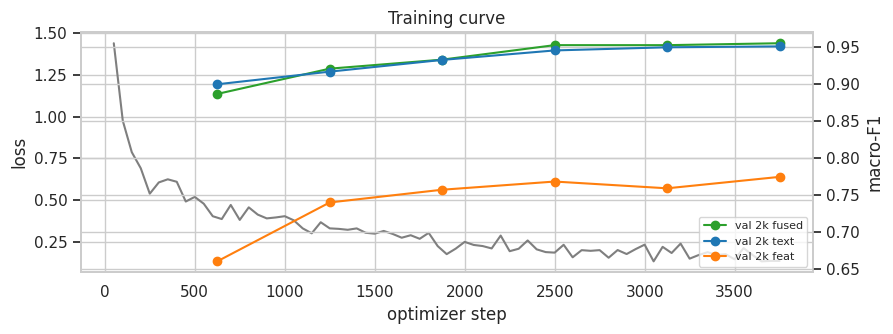

In [11]:
def length_grouped_batches(lengths, batch_size, rng, mega=50):
    idx = rng.permutation(len(lengths))
    batches = []
    for i in range(0, len(idx), batch_size * mega):
        group = sorted(idx[i:i + batch_size * mega], key=lambda j: lengths[j])
        batches += [group[k:k + batch_size] for k in range(0, len(group), batch_size)]
    rng.shuffle(batches)
    return batches

no_decay = ("bias", "norm")
bb = list(model.backbone.named_parameters())
head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
optimizer = torch.optim.AdamW([
    {"params": [p for n, p in bb if not any(k in n.lower() for k in no_decay)], "lr": LR, "weight_decay": WEIGHT_DECAY},
    {"params": [p for n, p in bb if any(k in n.lower() for k in no_decay)], "lr": LR, "weight_decay": 0.0},
    {"params": head_params, "lr": HEAD_LR, "weight_decay": WEIGHT_DECAY},
])
steps_per_epoch = math.ceil(len(train_seqs) / BATCH_SIZE / GRAD_ACCUM)
total_steps = steps_per_epoch * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
use_amp = DEVICE.type == "cuda"
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

rng = np.random.default_rng(RANDOM_STATE)
mon_idx = rng.choice(len(val), size=min(2000, len(val)), replace=False)
mon_seqs = [head_tail(ids_val[i]) for i in mon_idx]
mon_feats = F_val[mon_idx]
eval_every = max(total_steps // N_EVALS, 1)
lengths = [len(s) for s in train_seqs]
history, step, t_start, n_tok = [], 0, time.time(), 0
print(f"optimizer steps: {total_steps:,} (batch {BATCH_SIZE} x accum {GRAD_ACCUM})")

for epoch in range(EPOCHS):
    batches = length_grouped_batches(lengths, BATCH_SIZE, rng)
    net.train()
    running, n_since = 0.0, 0
    for b_i, batch in enumerate(batches):
        batch = np.asarray(batch)
        ids, mask = pad_batch([train_seqs[j] for j in batch])
        labels = torch.tensor(y_trn[batch], device=DEVICE)
        fx = torch.from_numpy(F_trn[batch]).to(DEVICE)
        if FEAT_NOISE > 0:
            fx = fx + FEAT_NOISE * torch.randn_like(fx)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            lg_fused, lg_text, lg_feat = net(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), feats=fx)
        loss = (F.cross_entropy(lg_fused.float(), labels)
                + AUX_W * F.cross_entropy(lg_text.float(), labels)
                + AUX_W * F.cross_entropy(lg_feat.float(), labels)) / GRAD_ACCUM
        scaler.scale(loss).backward()
        running += loss.item(); n_tok += int(mask.sum())
        if (b_i + 1) % GRAD_ACCUM == 0 or b_i == len(batches) - 1:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()
            step += 1; n_since += 1
            if step % 50 == 0 or step == total_steps:
                el = time.time() - t_start
                print(f"epoch {epoch + 1} step {step}/{total_steps} | loss {running / n_since:.4f} | "
                      f"lr {scheduler.get_last_lr()[0]:.2e} | {n_tok / el:,.0f} tok/s | "
                      f"elapsed {el / 60:.1f} min | ETA {el / step * (total_steps - step) / 60:.1f} min", flush=True)
                history.append({"step": step, "loss": running / n_since})
                running, n_since = 0.0, 0
            if step % eval_every == 0 or step == total_steps:
                p = predict_seqs(mon_seqs, mon_feats)
                r = {f"val2k_{k}": macro_f1(y_val[mon_idx], p[k].argmax(1)) for k in HEADS}
                history.append({"step": step, **r})
                print("   -> val 2k macro-F1 | " + " | ".join(f"{k}: {v:.4f}" for k, v in r.items()), flush=True)
                net.train()
print(f"training done in {(time.time() - t_start) / 60:.1f} min")

hist = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(9, 3.5))
h = hist.dropna(subset=["loss"]); ax.plot(h["step"], h["loss"], label="train loss", c="tab:gray")
ax2 = ax.twinx()
for k, c in zip(HEADS, ["tab:green", "tab:blue", "tab:orange"]):
    col = f"val2k_{k}"
    if col in hist:
        hh = hist.dropna(subset=[col]); ax2.plot(hh["step"], hh[col], "o-", c=c, label=f"val 2k {k}")
ax2.set_ylabel("macro-F1"); ax2.legend(loc="lower right", fontsize=8)
ax.set_xlabel("optimizer step"); ax.set_ylabel("loss"); ax.set_title("Training curve"); plt.tight_layout(); plt.show()

if SAVE_MODEL:
    torch.save(model.state_dict(), OUT_DIR / "mmbert_fusion.pt")

## Validation: fused vs text-only vs feature-only
All three heads come from the **same** network. `text` is the mmBERT branch alone (closest to the earlier head+tail run, now with 30k rows), `feat` is the feature MLP alone, and `fused` is the main output.

In [12]:
with timer("predict val (head+tail)"):
    val_ht = predict_head_tail(ids_val, F_val)
val_ch, val_ch_stats = (None, None)
if USE_CHUNKS:
    with timer("predict val (chunks)"):
        val_ch, val_ch_stats = predict_chunks(ids_val, F_val)

rows = []
for strat_name, probs in [("head+tail 1024", val_ht)] + ([("chunks 1024 (avg)", val_ch)] if val_ch else []):
    for k in HEADS:
        pred = probs[k].argmax(1)
        rows.append({"inputs": strat_name, "head": k, "macro_f1": macro_f1(y_val, pred), "accuracy": accuracy_score(y_val, pred),
                     **{f"f1_{c}": v for c, v in zip(CLASSES, f1_score(y_val, pred, average=None, labels=range(3)))}})
head_df = pd.DataFrame(rows)
display(head_df.style.background_gradient(subset=["macro_f1", "f1_human", "f1_ai", "f1_fusion"], cmap="Greens").format(precision=4))

[start] predict val (head+tail) ...
[done]  predict val (head+tail): 279.8s
[start] predict val (chunks) ...
[done]  predict val (chunks): 388.9s


,inputs,head,macro_f1,accuracy,f1_human,f1_ai,f1_fusion
0,head+tail 1024,fused,0.9596,0.9658,0.9372,0.9946,0.9469
1,head+tail 1024,text,0.9542,0.9613,0.9284,0.9941,0.9400
2,head+tail 1024,feat,0.7941,0.8216,0.7247,0.9509,0.7067
3,chunks 1024 (avg),fused,0.9463,0.9552,0.9128,0.9946,0.9314
4,chunks 1024 (avg),text,0.9440,0.9532,0.9088,0.9940,0.9291
5,chunks 1024 (avg),feat,0.7941,0.8216,0.7247,0.9509,0.7067


## Stage 2: LightGBM stacker on validation (5-fold OOF)
Inputs per text: fused / text / feature head probabilities (head+tail), chunk-probability statistics, raw handcrafted features, lang and domain (categorical). The stacker is trained only on the validation rows, which the transformer never saw, so its inputs are realistic. Out-of-fold predictions give an honest macro-F1. For test, the stacker is refit on all validation rows.

In [13]:
def stack_matrix(probs_ht, ch_stats, feat_df, df):
    parts = [pd.DataFrame(probs_ht[k], columns=[f"ht_{k}_{c}" for c in CLASSES]) for k in HEADS]
    lp = np.log(probs_ht["fused"] + 1e-7)
    parts.append(pd.DataFrame({"ht_fused_margin_fusion_human": lp[:, 2] - lp[:, 0],
                               "ht_fused_margin_ai_fusion": lp[:, 1] - lp[:, 2]}))
    if ch_stats is not None:
        parts.append(ch_stats.reset_index(drop=True))
        parts.append(pd.DataFrame({"ch_max_minus_mean_fusion": ch_stats["ch_max_fusion"] - ch_stats["ch_mean_fusion"],
                                   "ch_max_minus_mean_ai": ch_stats["ch_max_ai"] - ch_stats["ch_mean_ai"]}))
    parts.append(feat_df.reset_index(drop=True))
    X = pd.concat(parts, axis=1)
    X["lang"] = pd.Categorical(df[LANG].values, categories=LANGS)
    X["domain"] = pd.Categorical(df[DOMAIN].values, categories=DOMAINS)
    return X

def make_gbm():
    if HAS_LGB:
        return lgb.LGBMClassifier(n_estimators=700, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0,
                                  random_state=RANDOM_STATE, n_jobs=os.cpu_count(), verbose=-1)
    from sklearn.ensemble import HistGradientBoostingClassifier
    return HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05, categorical_features="from_dtype",
                                          random_state=RANDOM_STATE)

def oof_gbm(X, y, folds):
    oof = np.zeros((len(y), len(CLASSES)), dtype=np.float32)
    for tr, te in folds:
        m = make_gbm().fit(X.iloc[tr], y[tr])
        oof[te] = m.predict_proba(X.iloc[te])
    return oof

X_val_stack = stack_matrix(val_ht, val_ch_stats, feat_val, val)
skf = StratifiedKFold(n_splits=N_FOLDS_STACK, shuffle=True, random_state=RANDOM_STATE)
FOLDS = list(skf.split(np.zeros(len(val)), (val[LABEL] + "|" + val[DOMAIN]).values))

with timer("stacker OOF (all inputs)"):
    oof_stack = oof_gbm(X_val_stack, y_val, FOLDS)
with timer("GBM OOF (handcrafted features only, for reference)"):
    feat_only_cols = FEAT_COLS + ["lang", "domain"]
    oof_feat_only = oof_gbm(X_val_stack[feat_only_cols], y_val, FOLDS)
print(f"stacker OOF macro-F1          = {macro_f1(y_val, oof_stack.argmax(1)):.4f}")
print(f"features-only GBM OOF macro-F1 = {macro_f1(y_val, oof_feat_only.argmax(1)):.4f}")

[start] stacker OOF (all inputs) ...
[done]  stacker OOF (all inputs): 64.4s
[start] GBM OOF (handcrafted features only, for reference) ...
[done]  GBM OOF (handcrafted features only, for reference): 60.8s
stacker OOF macro-F1          = 0.9638
features-only GBM OOF macro-F1 = 0.8203


### Class-bias tuning for macro-F1 (nested)
Adds per-class offsets to the log-probabilities (human fixed at 0). The offsets are tuned on 4 folds and applied to the 5th, so the reported score is honest. The final offsets for test are tuned on all validation rows.

In [14]:
def fast_macro_f1(y, pred, k=len(CLASSES)):
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    return float(np.mean(2 * tp / np.maximum(2 * tp + fp + fn, 1)))

GRID = np.round(np.arange(-1.0, 1.0001, 0.05), 3)
def tune_bias(P, y):
    L = np.log(P + 1e-7)
    best, best_b = fast_macro_f1(y, L.argmax(1)), np.zeros(3)
    for a in GRID:
        for b in GRID:
            s = fast_macro_f1(y, (L + np.array([0.0, a, b])).argmax(1))
            if s > best + 1e-9:
                best, best_b = s, np.array([0.0, a, b])
    return best_b

def nested_bias_pred(P, y, folds):
    pred = np.zeros(len(y), dtype=int)
    for tr, te in folds:
        b = tune_bias(P[tr], y[tr])
        pred[te] = (np.log(P[te] + 1e-7) + b).argmax(1)
    return pred

def apply_bias(P, b):
    return (np.log(P + 1e-7) + b).argmax(1)

## Pick the best pipeline on validation

In [15]:
cands = {   # name -> validation probabilities (all honest: model never trained on val, stacker is OOF)
    "mmBERT + features, fused (head+tail)": val_ht["fused"],
    "features-only GBM": oof_feat_only,
    "stacker (fused probs + chunk stats + features)": oof_stack,
}
if val_ch:
    cands["mmBERT + features, fused (chunks avg)"] = val_ch["fused"]

rows = []
for name, P in cands.items():
    for bias in (False, True):
        pred = nested_bias_pred(P, y_val, FOLDS) if bias else P.argmax(1)
        rows.append({"pipeline": name, "bias_tuned": bias, "macro_f1": macro_f1(y_val, pred),
                     **{f"f1_{c}": v for c, v in zip(CLASSES, f1_score(y_val, pred, average=None, labels=range(3)))},
                     **{f"macro_f1_{l}": macro_f1(y_val[(val[LANG] == l).values], pred[(val[LANG] == l).values]) for l in LANGS}})
res = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(res.style.background_gradient(subset=[c for c in res.columns if c.startswith(("macro", "f1_"))], cmap="Greens").format(precision=4))

BEST = res.loc[0]
BEST_NAME, BEST_BIAS = BEST["pipeline"], bool(BEST["bias_tuned"])
best_val_pred = nested_bias_pred(cands[BEST_NAME], y_val, FOLDS) if BEST_BIAS else cands[BEST_NAME].argmax(1)
print(f"best: {BEST_NAME} | bias tuned: {BEST_BIAS} | val macro-F1 = {BEST['macro_f1']:.4f}\n")
print(classification_report(y_val, best_val_pred, target_names=CLASSES, digits=4))

,pipeline,bias_tuned,macro_f1,f1_human,f1_ai,f1_fusion,macro_f1_en-EN,macro_f1_de-DE
0,stacker (fused probs + chunk stats + features),False,0.9638,0.9443,0.9949,0.9522,0.9598,0.9786
1,stacker (fused probs + chunk stats + features),True,0.9637,0.9441,0.9949,0.9521,0.9601,0.9769
2,"mmBERT + features, fused (head+tail)",False,0.9596,0.9372,0.9946,0.9469,0.9558,0.9734
3,"mmBERT + features, fused (head+tail)",True,0.9594,0.9371,0.9947,0.9465,0.9555,0.9739
4,"mmBERT + features, fused (chunks avg)",True,0.9543,0.9289,0.9942,0.9398,0.9501,0.9694
5,"mmBERT + features, fused (chunks avg)",False,0.9463,0.9128,0.9946,0.9314,0.9427,0.9595
6,features-only GBM,True,0.8224,0.7443,0.9691,0.7538,0.8235,0.8187
7,features-only GBM,False,0.8203,0.7363,0.9688,0.7559,0.8221,0.8143


best: stacker (fused probs + chunk stats + features) | bias tuned: False | val macro-F1 = 0.9638

              precision    recall  f1-score   support

       human     0.9277    0.9614    0.9443      4900
          ai     0.9949    0.9950    0.9949      8954
      fusion     0.9665    0.9383    0.9522      6146

    accuracy                         0.9694     20000
   macro avg     0.9630    0.9649    0.9638     20000
weighted avg     0.9697    0.9694    0.9694     20000



### Confusion matrices and per-domain scores

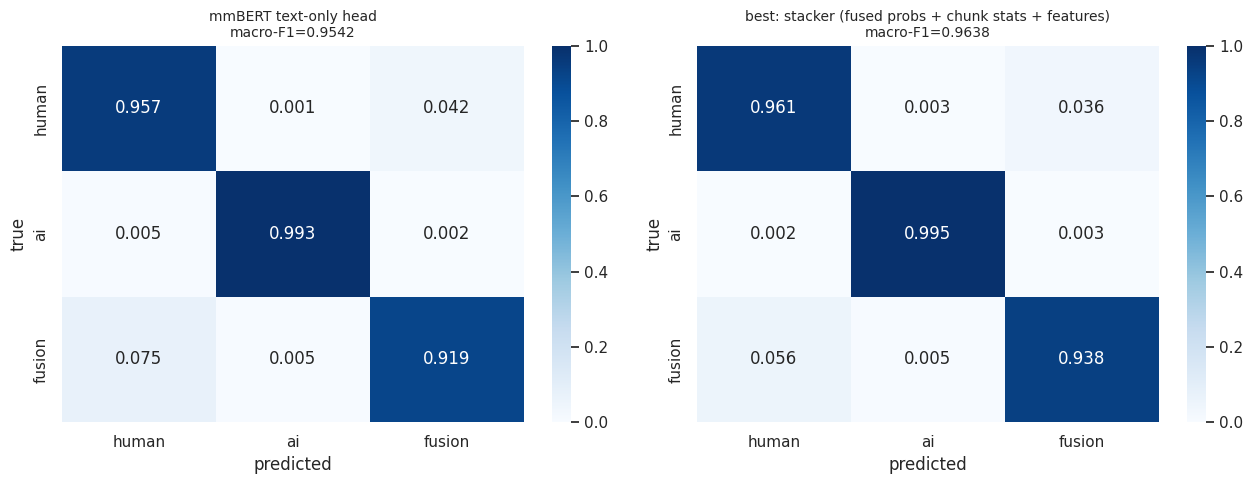

,lang,domain,n,text_only,best,delta
3,en-EN,blog_authorship_corpus,2977,0.8864,0.8849,-0.0015
8,en-EN,student_essays,3973,0.9744,0.9742,-0.0002
1,de-DE,gutenberg,31,0.8157,0.8157,0.0000
4,en-EN,cnn_news,3252,0.9910,0.9914,0.0003
0,de-DE,bundestag,3844,0.9733,0.9791,0.0057
7,en-EN,house_of_commons,2340,0.9680,0.9755,0.0075
5,en-EN,euro_court_cases,2025,0.9155,0.9760,0.0605
6,en-EN,gutenberg,508,0.8432,0.9192,0.0760
2,en-EN,arxiv_papers,1050,0.8301,0.9398,0.1096


In [16]:
base_pred = val_ht["text"].argmax(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, pred) in zip(axes, [("mmBERT text-only head", base_pred), (f"best: {BEST_NAME}", best_val_pred)]):
    cm = confusion_matrix(y_val, pred, labels=range(3))
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f"{name}\nmacro-F1={macro_f1(y_val, pred):.4f}", fontsize=10); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

v = val.assign(base=base_pred, best=best_val_pred, y=y_val)
dom = pd.DataFrame([{"lang": l, "domain": d, "n": len(g),
                     "text_only": macro_f1(g["y"], g["base"]), "best": macro_f1(g["y"], g["best"])}
                    for (l, d), g in v.groupby([LANG, DOMAIN])]).assign(delta=lambda x: x["best"] - x["text_only"])
display(dom.sort_values("delta").style.background_gradient(subset=["delta"], cmap="RdYlGn", vmin=-0.05, vmax=0.05).format(precision=4))

### Which stacker inputs matter? (LightGBM gain importance, model fit on all validation rows)

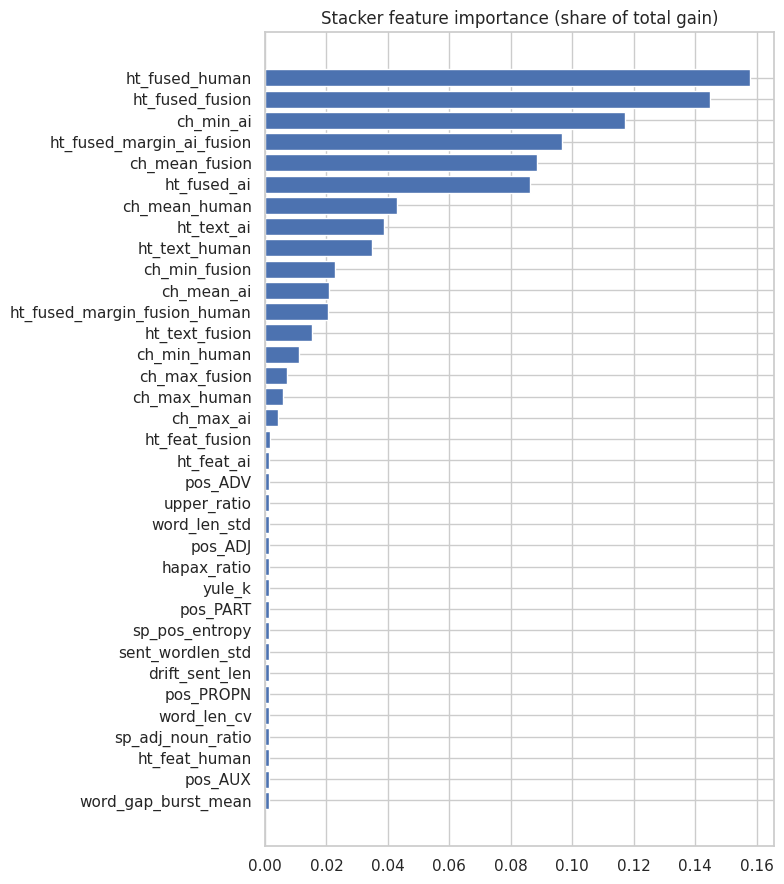

,gain share
model probs (head+tail),0.599
chunk stats,0.322
surface (burstiness/digits/non-ascii/commas/...),0.046
spaCy stylometry,0.032
lang/domain,0.000


In [17]:
final_stacker = make_gbm().fit(X_val_stack, y_val)
if HAS_LGB:
    imp = pd.Series(final_stacker.booster_.feature_importance("gain"), index=X_val_stack.columns).sort_values(ascending=False)
    top = imp.head(35)[::-1]
    plt.figure(figsize=(8, 9)); plt.barh(top.index, top.values / imp.sum())
    plt.title("Stacker feature importance (share of total gain)"); plt.tight_layout(); plt.show()
    grp = imp.groupby(lambda c: "model probs (head+tail)" if c.startswith("ht_") else "chunk stats" if c.startswith("ch_")
                      else "spaCy stylometry" if c.startswith(("pos_", "sp_")) else "lang/domain" if c in ("lang", "domain")
                      else "surface (burstiness/digits/non-ascii/commas/...)").sum()
    display((grp / grp.sum()).sort_values(ascending=False).to_frame("gain share").style.format("{:.3f}"))

## Predict test & save submission
Runs the same inference as the chosen pipeline. If the stacker or bias won, it uses `final_stacker` (fit on all validation rows) and offsets tuned on all validation rows. Also saves raw probabilities (`probs_mmbert_features.npz`) for later ensembling.

In [18]:
with timer("predict test (head+tail)"):
    test_ht = predict_head_tail(ids_test, F_test)
test_ch, test_ch_stats = (None, None)
if USE_CHUNKS:
    with timer("predict test (chunks)"):
        test_ch, test_ch_stats = predict_chunks(ids_test, F_test)

test_cands = {
    "mmBERT + features, fused (head+tail)": lambda: test_ht["fused"],
    "features-only GBM": lambda: make_gbm().fit(X_val_stack[feat_only_cols], y_val).predict_proba(
        stack_matrix(test_ht, test_ch_stats, feat_test, test)[feat_only_cols]),
    "stacker (fused probs + chunk stats + features)": lambda: final_stacker.predict_proba(
        stack_matrix(test_ht, test_ch_stats, feat_test, test)),
    "mmBERT + features, fused (chunks avg)": lambda: test_ch["fused"],
}
test_P = test_cands[BEST_NAME]()
if BEST_BIAS:
    bias = tune_bias(cands[BEST_NAME], y_val)
    print("class offsets (human, ai, fusion):", bias)
    test_pred_id = apply_bias(test_P, bias)
else:
    test_pred_id = test_P.argmax(1)
test_pred = np.array(CLASSES)[test_pred_id]

sub = sample_sub[["id"]].merge(pd.DataFrame({"id": test["id"].values, "label": test_pred}), on="id", how="left")
assert sub["label"].notna().all() and len(sub) == len(sample_sub) and set(sub["label"]) <= set(CLASSES)
SUB_PATH = OUT_DIR / "submission.csv"
sub.to_csv(SUB_PATH, index=False)
print(f"pipeline: {BEST_NAME} (bias={BEST_BIAS}) | saved {SUB_PATH.resolve()} {sub.shape}")

np.savez_compressed(OUT_DIR / "probs_mmbert_features.npz",
                    val_ids=val["id"].values, test_ids=test["id"].values, val_best=cands[BEST_NAME], test_best=test_P,
                    **{f"val_ht_{k}": val_ht[k] for k in HEADS}, **{f"test_ht_{k}": test_ht[k] for k in HEADS})

display(sub.head())
display(pd.concat({"train share": train[LABEL].value_counts(normalize=True),
                   "test pred share": sub["label"].value_counts(normalize=True)}, axis=1).loc[CLASSES].round(3))
os.chdir(OUT_DIR)
display(FileLink(SUB_PATH.name))

[start] predict test (head+tail) ...
[done]  predict test (head+tail): 340.2s
[start] predict test (chunks) ...
[done]  predict test (chunks): 460.3s
pipeline: stacker (fused probs + chunk stats + features) (bias=False) | saved /kaggle/working/submission.csv (25000, 2)


,id,label
0,8ff2d1,ai
1,a261cf,human
2,ad5614,fusion
3,3a23ac,ai
4,28b4e5,ai


,train share,test pred share
label,,
human,0.245,0.260
ai,0.448,0.514
fusion,0.307,0.225


/kaggle/working/submission.csv